# 03. Quantitative Data Charts in Notebooks

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/yuichi110/drawlib/blob/main/docs/jupyter/en/03_data_charts.ipynb)

Drawlib includes 10 quantitative chart components (`BarChart`, `LineChart`, `AreaChart`, `PieChart`, `RadarChart`, `BoxChart`, `ScatterChart`, `GanttChart`, `HeatmapChart`, `HeatmapOverlay`) that sit alongside callouts, icons, and architecture diagrams on a single canvas.

![Multi-Chart Executive Dashboard on a Single Canvas](https://www.drawlib.com/jupyter/images/03_data_charts/03_hero_kpi_charts.png)

*Multi-Chart Executive Dashboard on a Single Canvas*

---

## 1. Computing Metrics in Python Cells

Because notebook cells share state, you can aggregate or transform data in standard Python cells before passing the series into a Drawlib chart:

In [ ]:
!pip install -q drawlib

In [1]:
raw_latencies_ms = {
    "v0.3.8": [48.2, 46.0, 49.5, 45.1],
    "v0.3.9": [34.0, 32.5, 35.1, 31.8],
    "v0.3.10": [22.4, 21.0, 23.1, 20.5],
    "v0.3.11": [15.8, 14.9, 16.2, 14.5],
}

releases = list(raw_latencies_ms.keys())
mean_latencies = [round(sum(vals) / len(vals), 1) for vals in raw_latencies_ms.values()]
for rel, avg in zip(releases, mean_latencies, strict=True):
    print(f"{rel}: mean={avg:.1f} ms")
mean_latencies

v0.3.8: mean=47.2 ms
v0.3.9: mean=33.4 ms
v0.3.10: mean=21.8 ms
v0.3.11: mean=15.3 ms


[47.2, 33.4, 21.8, 15.3]

---

## 2. Plotting Computed Series with Annotation Cards

Remember that all `Charts` use a **Bottom-Left `(x0, y0)`** coordinate anchor:

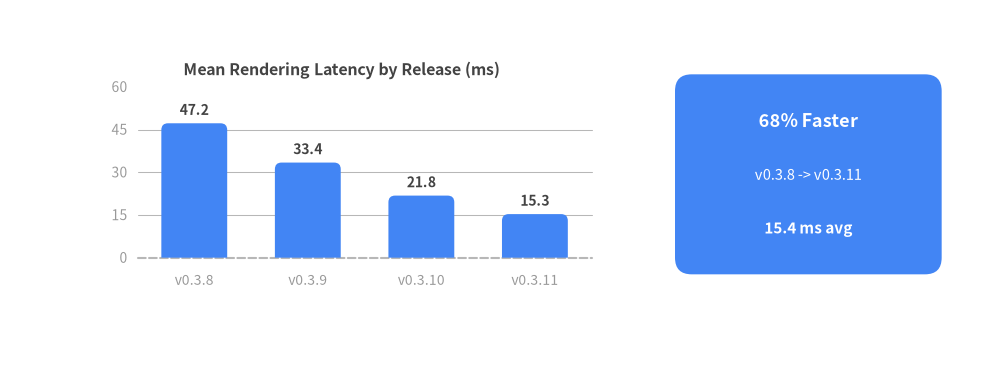

In [2]:
from drawlib.canvas import show, setup
from drawlib.charts.bar import BarChart
from drawlib.shapes import rectangle
from drawlib.styles import Styles
from drawlib.text import text

setup(width=120, height=44, cwd=True)

chart = BarChart(
    axis_line_style=Styles.MutedDashed,
    categories=releases,
    width=66.0,
    height=30.0,
    bar_width_ratio=0.58,
    bar_r=0.8,
    axis_text_style=Styles.Muted.patch(text_size=10.0),
    grid_style=Styles.MutedThin,
    value_text_style=Styles.DarkBold.patch(text_size=10.0),
    value_format="{:.1f}",
    title="Mean Rendering Latency by Release (ms)",
    title_style=Styles.DarkBold.patch(text_size=11.5),
)
chart.add_series("Mean Latency", mean_latencies, style=Styles.PrimaryFlat)
chart.configure_y_axis(min_value=0.0, max_value=60.0, tick_step=15.0)
chart.draw(xy=(8.0, 8.0))

# Summary Callout Card on the Right (Center Anchor)
rectangle((97.0, 23.0), width=32.0, height=24.0, style=Styles.PrimaryFlat.patch(shape_r=2.0))
text((97.0, 29.5), "68% Faster", style=Styles.WhiteBold.patch(text_size=13))
text((97.0, 23.0), "v0.3.8 -> v0.3.11", style=Styles.White.patch(text_size=10.5))
text((97.0, 16.5), "15.4 ms avg", style=Styles.WhiteBold.patch(text_size=11))

show()